In [1]:
from typing_extensions import List, Literal
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.5)

In [2]:
llm.invoke("hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "hi". We should greet back. Keep it friendly.'}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 72, 'total_tokens': 114, 'completion_time': 0.088829312, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.014334294, 'prompt_tokens_details': None, 'queue_time': 0.209366092, 'total_time': 0.103163606}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0ece8-049d-7a91-9e1f-18bcda933054-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 42, 'total_tokens': 114, 'output_token_details': {'reasoning': 24}})

In [3]:
from typing import Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage

### State — added `selected_tools` for the Jev router

In [4]:
class State(BaseModel):
    messages: Annotated[list[AnyMessage], add_messages] = Field(default_factory=list)
    response: str = ""
    selected_tools: list[str] = Field(default_factory=list)  # filled by router_node
    general_chat: bool = False  # True when Jev is confident no tool is needed at all

In [5]:
import sqlite3
DB_PATH = "clinic.db"
conn = sqlite3.connect(DB_PATH, check_same_thread=False)
conn.execute("PRAGMA foreign_keys = ON")
cur = conn.cursor()

In [6]:
import re

PHONE_PATTERN = re.compile(r"^(?:0020|20|\+20)?0?1[0-25]\d{8}$")

def is_valid_phone(phone: str) -> bool:
    return bool(PHONE_PATTERN.match(re.sub(r"[\s\-]", "", phone)))

print(is_valid_phone("201017989362"))

True


In [7]:
def normalize_phone(phone: str) -> str:
    """Convert any phone format into the DB's stored format: 0XXXXXXXXXX."""
    digits = re.sub(r"\D", "", phone)  # strip spaces, dashes, +, etc.

    if digits.startswith("0020"):
        digits = digits[2:]         
    if digits.startswith("20") and len(digits) == 12:
        digits = "0" + digits[2:]     

    return digits

In [8]:
from langchain_core.tools import tool

@tool
def search_patient(name: str | None = None, phone: str | None = None) -> str:
    """Use this tool to look up a patient by phone number or name. Prefer the phone number over the name when both are given."""

    if phone and is_valid_phone(phone):
        normalized = normalize_phone(phone)
        cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
        row = cur.fetchone()
        if row:
            patient_id, patient_name = row
            return f"id={patient_id}, name={patient_name}"
        return f"No patient found with phone '{phone}'."

    if name:
        cur.execute("SELECT id, name, phone FROM patients WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()
        if rows:
            return "\n".join(f"id={r[0]}, name={r[1]}, phone={r[2]}" for r in rows)
        return f"No patient found with name '{name}'."

    return "Please provide a patient name or phone number to search."

@tool
def get_patient_history(name: str | None = None, phone: str | None = None) -> str:
    """Use this tool to look up a patient's history of past appointments by phone number or name. Prefer the phone number over the name when both are given."""

    if phone and is_valid_phone(phone):
        normalized = normalize_phone(phone)
        cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
        row = cur.fetchone()

        if row:
            patient_id, patient_name = row
            cur.execute(
                """SELECT s.date, s.time, d.name, a.status, a.reason
                   FROM appointments a
                   JOIN slots s ON a.slot_id = s.id
                   JOIN doctors d ON a.doctor_id = d.id
                   WHERE a.patient_id = ?
                   ORDER BY s.date, s.time""",
                (patient_id,)
            )
            appointments = cur.fetchall()

            if not appointments:
                return f"{patient_name} (id={patient_id}) has no appointment history."

            lines = [f"{date} {time} with {doctor} - {status} ({reason})"
                     for date, time, doctor, status, reason in appointments]
            return f"History for {patient_name} (id={patient_id}):\n" + "\n".join(lines)

        return f"No patient found with phone '{phone}'."

    if name:
        cur.execute("SELECT id, name, phone FROM patients WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()
        if rows:
            return "\n".join(f"id={r[0]}, name={r[1]}, phone={r[2]}" for r in rows)
        return f"No patient found with name '{name}'."

    return "Please provide a patient name or phone number."

In [9]:
@tool
def list_doctors(speciality: str | None = None) -> str:
    """Use this tool to look up the clinic's doctors. Optionally filter by speciality (e.g. 'dentist', 'cardiology'); leave it empty to list all doctors."""

    if speciality:
        cur.execute("SELECT id, name, specialty FROM doctors WHERE specialty LIKE ?", (f"%{speciality}%",))
    else:
        cur.execute("SELECT id, name, specialty FROM doctors")
    rows = cur.fetchall()

    if rows:
        return "\n".join(f"id={r[0]}, name={r[1]}, specialty={r[2]}" for r in rows)
    if speciality:
        return f"No doctors found with speciality '{speciality}'."
    return "No doctors found."

In [10]:
from datetime import datetime

def is_valid_date(date_str: str) -> bool:
    """Check that the date is in YYYY-MM-DD format and is a real calendar date."""
    try:
        datetime.strptime(date_str.strip(), "%Y-%m-%d")
        return True
    except ValueError:
        return False

print(is_valid_date("2026-09-28"))  # True
print(is_valid_date("2026-02-30"))  # False (Feb 30 doesn't exist)
print(is_valid_date("28-09-2026"))  # False (wrong order)

True
False
False


In [11]:
@tool
def check_availability(doctor_id: str | None = None, date: str | None = None) -> str:
    """Use this tool to look up the available (free) slots for a doctor on a specific date. Requires doctor_id and date, and the date must be in YYYY-MM-DD format."""
    if date and is_valid_date(date):
        cur.execute("SELECT id, time FROM slots WHERE doctor_id = ? AND date = ? AND is_booked = 0 ORDER BY time", (doctor_id, date))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"id={r[0]}, time={r[1]}" for r in rows)
        return f"No available slots for doctor {doctor_id} on {date}."

    return "Please provide a doctor_id and a date in YYYY-MM-DD format."

In [12]:
@tool
def get_treatment_price(name: str | None = None) -> str:
    """Use this tool to look up the price of a treatment by name."""
    if name:
        cur.execute("SELECT name, price FROM treatments WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"name={r[0]}, price={r[1]} EGP" for r in rows)
        return f"No treatment found with name '{name}'."

    return "Please provide a treatment name."

In [13]:
@tool
def get_clinic_info(topic: str | None = None) -> str:
    """Use this tool to look up general clinic information (e.g. hours, address, insurance) by topic."""
    if topic:
        cur.execute("SELECT topic, content FROM clinic_info WHERE topic LIKE ?", (f"%{topic}%",))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"{r[0]}: {r[1]}" for r in rows)
        return f"No clinic information found for topic '{topic}'."

    return "Please provide a topic (e.g. hours, address, insurance)."

In [14]:
from langgraph.types import interrupt

@tool
def book_appointment(patient_id: str | None = None, doctor_id: str | None = None, slot_id: str | None = None) -> str:
    """Use this tool to book an appointment for a patient with a doctor at a specific slot.
    Requires patient_id, doctor_id, and slot_id. This is a write action and requires human approval."""

    if not (patient_id and doctor_id and slot_id):
        return "Please provide patient_id, doctor_id, and slot_id."

    cur.execute("SELECT name FROM patients WHERE id = ?", (patient_id,))
    patient = cur.fetchone()
    if not patient:
        return f"No patient found with id '{patient_id}'."

    cur.execute("SELECT date, time, doctor_id, is_booked FROM slots WHERE id = ?", (slot_id,))
    slot = cur.fetchone()
    if not slot:
        return f"No slot found with id '{slot_id}'."
    date, time, slot_doctor_id, is_booked = slot
    if str(slot_doctor_id) != str(doctor_id):
        return f"Slot {slot_id} does not belong to doctor {doctor_id}."
    if is_booked:
        return f"Slot {slot_id} on {date} at {time} is already booked."

    decision = interrupt({
        "action": "book_appointment",
        "patient_id": patient_id,
        "patient_name": patient[0],
        "doctor_id": doctor_id,
        "slot_id": slot_id,
        "date": date,
        "time": time,
    })

    if not decision.get("approved"):
        return "Booking not approved — cancelled."

    # re-check: the slot may have been booked by someone else while waiting for approval
    cur.execute("SELECT is_booked FROM slots WHERE id = ?", (slot_id,))
    current = cur.fetchone()
    if not current or current[0]:
        return f"Slot {slot_id} is no longer available — it was booked while waiting for approval."

    cur.execute(
        "INSERT INTO appointments (patient_id, doctor_id, slot_id, status, reason) VALUES (?, ?, ?, 'booked', ?)",
        (patient_id, doctor_id, slot_id, decision.get("reason", "")),
    )
    cur.execute("UPDATE slots SET is_booked = 1 WHERE id = ?", (slot_id,))
    conn.commit()

    return f"Appointment booked: {patient[0]} with doctor {doctor_id} on {date} at {time}."

In [15]:
@tool
def cancel_appointment(appointment_id: str | None = None, reason: str | None = None) -> str:
    """Use this tool to cancel an existing booked appointment. Requires appointment_id;
    reason is optional context for the cancellation. This is a write action and requires human approval."""

    if not appointment_id:
        return "Please provide an appointment_id."

    cur.execute(
        """SELECT a.status, a.slot_id, a.patient_id, s.date, s.time, p.name
           FROM appointments a
           JOIN slots s ON a.slot_id = s.id
           JOIN patients p ON a.patient_id = p.id
           WHERE a.id = ?""",
        (appointment_id,)
    )
    row = cur.fetchone()
    if not row:
        return f"No appointment found with id '{appointment_id}'."

    status, slot_id, patient_id, date, time, patient_name = row
    if status != "booked":
        return f"Appointment {appointment_id} is already '{status}' — nothing to cancel."

    decision = interrupt({
        "action": "cancel_appointment",
        "appointment_id": appointment_id,
        "patient_name": patient_name,
        "date": date,
        "time": time,
        "cancellation_reason": reason,
    })

    if not decision.get("approved"):
        return "Cancellation not approved."

    cur.execute("SELECT status FROM appointments WHERE id = ?", (appointment_id,))
    current = cur.fetchone()
    if not current or current[0] != "booked":
        return f"Appointment {appointment_id} is no longer booked — nothing to cancel."

    cur.execute("UPDATE appointments SET status = 'cancelled' WHERE id = ?", (appointment_id,))
    cur.execute("UPDATE slots SET is_booked = 0 WHERE id = ?", (slot_id,))
    conn.commit()

    return f"Appointment {appointment_id} for {patient_name} on {date} at {time} cancelled."

In [16]:
@tool
def reschedule_appointment(appointment_id: str | None = None, new_slot_id: str | None = None) -> str:
    """Use this tool to move an existing booked appointment to a different slot.
    Requires appointment_id and new_slot_id. This is a write action and requires human approval."""

    if not (appointment_id and new_slot_id):
        return "Please provide an appointment_id and a new_slot_id."

    cur.execute(
        """SELECT a.status, a.slot_id, a.doctor_id, p.name, s.date, s.time
           FROM appointments a
           JOIN slots s ON a.slot_id = s.id
           JOIN patients p ON a.patient_id = p.id
           WHERE a.id = ?""",
        (appointment_id,)
    )
    row = cur.fetchone()
    if not row:
        return f"No appointment found with id '{appointment_id}'."

    status, old_slot_id, doctor_id, patient_name, old_date, old_time = row
    if status != "booked":
        return f"Appointment {appointment_id} is '{status}' — only booked appointments can be rescheduled."

    cur.execute("SELECT doctor_id, date, time, is_booked FROM slots WHERE id = ?", (new_slot_id,))
    new_slot = cur.fetchone()
    if not new_slot:
        return f"No slot found with id '{new_slot_id}'."
    new_doctor_id, new_date, new_time, new_is_booked = new_slot
    if str(new_doctor_id) != str(doctor_id):
        return f"Slot {new_slot_id} belongs to a different doctor than the current appointment."
    if new_is_booked:
        return f"Slot {new_slot_id} on {new_date} at {new_time} is already booked."
    if str(new_slot_id) == str(old_slot_id):
        return "That is already the appointment's current slot."

    decision = interrupt({
        "action": "reschedule_appointment",
        "appointment_id": appointment_id,
        "patient_name": patient_name,
        "old_date": old_date,
        "old_time": old_time,
        "new_date": new_date,
        "new_time": new_time,
    })

    if not decision.get("approved"):
        return "Reschedule not approved."


    cur.execute("SELECT status, slot_id FROM appointments WHERE id = ?", (appointment_id,))
    current = cur.fetchone()
    if not current or current[0] != "booked" or str(current[1]) != str(old_slot_id):
        return f"Appointment {appointment_id} changed while waiting for approval — please retry."

    cur.execute("SELECT is_booked FROM slots WHERE id = ?", (new_slot_id,))
    new_current = cur.fetchone()
    if not new_current or new_current[0]:
        return f"Slot {new_slot_id} is no longer available — it was booked while waiting for approval."

    cur.execute("UPDATE slots SET is_booked = 0 WHERE id = ?", (old_slot_id,))
    cur.execute("UPDATE slots SET is_booked = 1 WHERE id = ?", (new_slot_id,))
    cur.execute("UPDATE appointments SET slot_id = ? WHERE id = ?", (new_slot_id, appointment_id))
    conn.commit()

    return f"Appointment {appointment_id} for {patient_name} rescheduled from {old_date} {old_time} to {new_date} {new_time}."

In [17]:
@tool
def register_patient(name: str | None = None, phone: str | None = None, dob: str | None = None) -> str:
    """Use this tool to register a new patient. Requires name, phone, and dob (YYYY-MM-DD).
    This is a write action and requires human approval."""

    if not (name and phone and dob):
        return "Please provide name, phone, and dob (YYYY-MM-DD)."

    if not is_valid_phone(phone):
        return f"'{phone}' is not a valid phone number."
    if not is_valid_date(dob):
        return f"'{dob}' is not a valid date. Please use YYYY-MM-DD."

    normalized = normalize_phone(phone)
    cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
    existing = cur.fetchone()
    if existing:
        return f"A patient with this phone number already exists: id={existing[0]}, name={existing[1]}."

    decision = interrupt({
        "action": "register_patient",
        "name": name,
        "phone": normalized,
        "dob": dob,
    })

    if not decision.get("approved"):
        return "Registration not approved."

    # re-check: someone else may have registered this phone number while waiting for approval
    cur.execute("SELECT id FROM patients WHERE phone = ?", (normalized,))
    if cur.fetchone():
        return f"A patient with phone '{normalized}' was registered while waiting for approval."

    cur.execute(
        "INSERT INTO patients (name, phone, dob) VALUES (?, ?, ?)",
        (name, normalized, dob),
    )
    conn.commit()

    return f"Patient registered: id={cur.lastrowid}, name={name}, phone={normalized}."

In [18]:
tools = [
    search_patient,
    get_patient_history,
    list_doctors,
    check_availability,
    get_treatment_price,
    get_clinic_info,
    book_appointment,
    cancel_appointment,
    reschedule_appointment,
    register_patient,
]
llm_with_tools = llm.bind_tools(tools)  # fallback: all 10 tools, used when Jev isn't confident

### Jev router — three outcomes per message, using the free local model

Swapped the paid TypeSafe API for the open-source clone (https://github.com/ikermoel/open-alternative-jev):
same typed choice + confidence pattern, but it runs locally on your own GPU/CPU, no API key, no cost.

In [19]:
# installed from git (not on PyPI): uv add "open-alternative-jev[quant] @ git+https://github.com/ikermoel/open-alternative-jev"
import torch
from so1 import Decider, Choice

assert torch.cuda.is_available(), "CUDA torch build required - see pyproject [tool.uv.sources]"

# Qwen3.6-27B needs ~30 GB VRAM in 8-bit; the 4B model fits a 12 GB GPU at full bf16 precision.
# loads once; keep this cell's output alive rather than re-running it per call
jev_decider = Decider.from_pretrained("Qwen/Qwen3.5-4B", backend="hf", dtype=torch.bfloat16)

D:\d\NLP\clinic_zero\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]


Loading weights:   0%|          | 1/426 [00:00<03:16,  2.16it/s]


Loading weights:   0%|          | 2/426 [00:00<02:38,  2.67it/s]


Loading weights:   4%|▍         | 18/426 [00:00<00:13, 30.88it/s]


Loading weights:   6%|▌         | 25/426 [00:01<00:13, 30.10it/s]

... (59 outputs left out)


Loading weights:  96%|█████████▌| 407/426 [00:12<00:00, 28.79it/s]


Loading weights:  97%|█████████▋| 412/426 [00:12<00:00, 25.69it/s]


Loading weights:  98%|█████████▊| 416/426 [00:12<00:00, 25.94it/s]


Loading weights: 100%|██████████| 426/426 [00:12<00:00, 33.70it/s]

In [20]:
TOOL_DESCRIPTIONS = "\n".join(f"- {t.name}: {t.description}" for t in tools)
CONFIDENCE_THRESHOLD = 0.75

# Jev's classes = every tool name, plus general_chat for messages that need no tool at all
TOOL_LABELS = [t.name for t in tools] + ["general_chat"]


def classify_with_jev(user_message: str, tool_descriptions: str) -> dict:
    """Runs the local open-alternative-jev model to classify which tool (if any) this message needs."""
    decisions = jev_decider.decide(
        state=f"{tool_descriptions}\n\nUser message: {user_message}",
        questions=[Choice("route", TOOL_LABELS)],
        mode="separate",  # avoids the packed-mode cross-question contamination noted in the repo's README
    )
    result = decisions[0]
    return {"label": result.choice, "confidence": result.confidence}


def router_node(state: State) -> State:
    last_user_msg = state.messages[-1].content
    classification = classify_with_jev(last_user_msg, TOOL_DESCRIPTIONS)
    label = classification["label"]
    confidence = classification["confidence"]

    if confidence < CONFIDENCE_THRESHOLD:
        # not confident either way -> safest fallback: give the agent every tool
        return {"selected_tools": [], "general_chat": False}

    if label == "general_chat":
        # confident this needs no tool at all -> bind zero tools, pure reasoning
        return {"selected_tools": [], "general_chat": True}

    # confident about a specific tool
    return {"selected_tools": [label], "general_chat": False}

In [21]:
from langchain_core.messages import SystemMessage

SYSTEM_PROMPT = """You are ClinicDesk, the front-desk assistant for a dental clinic.

Use the available tools to look up patients, doctors, availability, treatment prices,
and clinic info, and to book, cancel, or reschedule appointments, or register new patients.

Always confirm the specific patient, doctor, date, and time with the user before calling
a write tool (book_appointment, cancel_appointment, reschedule_appointment, register_patient).
Never invent ids, dates, or prices — look them up with the read tools first."""

def agent_node(state: State) -> State:
    if state.general_chat:
        llm_scoped = llm  # Jev is confident no tool is needed -> pure reasoning, no tools bound
    elif state.selected_tools:
        active_tools = [t for t in tools if t.name in state.selected_tools]
        llm_scoped = llm.bind_tools(active_tools)
    else:
        llm_scoped = llm_with_tools  # not confident either way -> fall back to the full toolset

    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state.messages
    response = llm_scoped.invoke(messages)
    return {"messages": [response]}

### Graph — router_node runs once per turn, before agent_node

Fixed from the previous version: removed the redundant `tools -> END` edge.
`tools_condition` already sends `agent_node -> END` when there's no tool call, so `tools` should only ever loop back to `agent_node`.

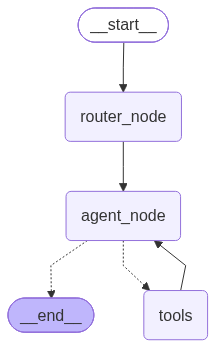

In [22]:
from IPython.display import Image, display
from langgraph.checkpoint.sqlite import SqliteSaver

checkpoint_conn = sqlite3.connect("checkpoints.sqlite", check_same_thread=False)
checkpointer = SqliteSaver(checkpoint_conn)
checkpointer.setup()

graph = StateGraph(State)

graph.add_node("router_node", router_node)
graph.add_node("agent_node", agent_node)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "router_node")
graph.add_edge("router_node", "agent_node")
graph.add_conditional_edges("agent_node", tools_condition)
graph.add_edge("tools", "agent_node")

graph_builder = graph.compile(checkpointer=checkpointer)

display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [23]:
from langchain_core.messages import HumanMessage
from langgraph.types import Command

# thread_id is the checkpointer's key: every invoke/stream call scoped to the same
# thread_id shares message history and lets an interrupt() pause/resume correctly.
# use a new thread_id per conversation/patient session.
config = {"configurable": {"thread_id": "3"}}

def run_turn(user_text: str, graph_to_run=None, cfg=None):
    graph_to_run = graph_to_run or graph_builder
    cfg = cfg or config
    result = graph_to_run.invoke({"messages": [HumanMessage(content=user_text)]}, config=cfg)

    while "__interrupt__" in result:
        payload = result["__interrupt__"][0].value
        print("Needs human approval:", payload)
        approved = input("Approve? (y/n): ").strip().lower() == "y"
        result = graph_to_run.invoke(Command(resume={"approved": approved}), config=cfg)

    print(result["messages"][-1].content)
    return result

run_turn("Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.")

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Got it! To set everything up I’ll need:

1. **Your full name** (as it appears on your patient record)  
2. **Your phone number** (so I can locate or create your patient profile)  

You mentioned “next Monday.” Today is September 29, 2026, so next Monday is **October 5, 2026**. Does that date work for you? Once I have your name and phone number, I’ll check Dr. Ahmed Hassan’s schedule for that day and confirm an available time slot before booking.


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='23b7de20-2277-4bf0-89a5-dbcae44786ff'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7af2829e-0b4b-4cd9-99b7-e6952700a01a'),
  AIMessage(content='Sure thing! I can help you schedule that.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your patient record)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The date you’d like** – you mentioned “next Monday.”\u202fBased on today’s date (September\u202f29,\u202f2026), next Monday would be **October\u202f5,\u202f2026**. Does that work for you?\n\nOnce I have your name and phone number, I’ll check Dr.\u202fAhmed\u202fHassan’s availability on that day and confirm the exact time slot before finalizing the booking.', additio

### LangSmith setup — comparing token usage with vs. without Jev

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
os.environ["LANGSMITH_TRACING"] = "true"
assert os.getenv("LANGSMITH_API_KEY"), "Set LANGSMITH_API_KEY in .env (smith.langchain.com -> Settings -> API Keys)"

### Baseline graph — no router_node, always binds all 10 tools

Same nodes, minus `router_node`. This is your "without Jev" control.

In [25]:
def agent_node_baseline(state: State) -> State:
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state.messages
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

baseline_graph = StateGraph(State)
baseline_graph.add_node("agent_node", agent_node_baseline)
baseline_graph.add_node("tools", ToolNode(tools))

baseline_graph.add_edge(START, "agent_node")
baseline_graph.add_conditional_edges("agent_node", tools_condition)
baseline_graph.add_edge("tools", "agent_node")

baseline_builder = baseline_graph.compile(checkpointer=checkpointer)

### Running the comparison

1. Pick a fixed set of test messages (the same ones for both runs) — e.g. a booking request, a cancellation, a price question, a general greeting.
2. Run them through the **Jev graph**, with a fresh `thread_id`, inside `tracing_context(project_name="clinicdesk-with-jev")`.
3. Switch to `tracing_context(project_name="clinicdesk-without-jev")`, and run the *same* messages through `baseline_builder` with another fresh `thread_id`.
4. Open [smith.langchain.com](https://smith.langchain.com), open each project, and look at the **Runs** table — the "Total Tokens" column per run is your comparison. Sum or average across your test set to get one number per condition.
5. Since your router is confidence-gated, also check what fraction of "with-jev" runs actually got scoped (`selected_tools` non-empty) vs. fell back to all 10 tools — that tells you how much of the token savings you can realistically expect in practice, not just in the best case.

In [26]:
from langsmith import tracing_context

test_messages = [
    "Hi, I want to book a checkup with a dentist next week.",
    "I need to cancel my appointment.",
    "How much does a root canal cost?",
    "Hello, what are your clinic hours?",
]

# tracing_context sets the project per run; changing os.environ["LANGCHAIN_PROJECT"] mid-session
# does nothing because langsmith caches the project name after the first traced call.

# --- with Jev ---
with tracing_context(project_name="clinicdesk-with-jev"):
    for i, msg in enumerate(test_messages):
        run_turn(msg, graph_to_run=graph_builder, cfg={"configurable": {"thread_id": f"jev-test-{i}"}})

# --- without Jev (baseline) ---
with tracing_context(project_name="clinicdesk-without-jev"):
    for i, msg in enumerate(test_messages):
        run_turn(msg, graph_to_run=baseline_builder, cfg={"configurable": {"thread_id": f"baseline-test-{i}"}})

Got it! To secure a slot for next week, I’ll need a few details:

1. **Which dentist would you like?**  
   - **Dr. Ahmed Hassan** – General Dentistry  
   - **Dr. Salma Youssef** – Pediatric Dentistry (ideal for children)

2. **Patient’s full name**  
3. **Contact phone number**  

Once I have that information, I’ll look up the available times for the chosen dentist and confirm the appointment with you.


I’m happy to cancel it for you. Could you let me know:

1. The name the appointment is under (your full name)  
2. The date and time of the appointment you’d like to cancel  
3. Which dentist or doctor the appointment was with (if you have that information)

With those details I can locate the correct booking and confirm before canceling.


A root canal treatment costs **3,500 EGP** at our clinic. Let me know if you’d like to schedule an appointment or need any additional information!


Our clinic is open **Saturday through Thursday** from **10:00 AM to 5:00 PM**. We’re closed on **Fridays**. Let us know if you’d like to schedule an appointment or need any other information!


Sure thing! I can help you set that up.

To get everything booked, I’ll need a few details:

1. **Your name** (as it appears on your records)  
2. **Phone number** (so I can look up or create your patient profile)  
3. **Date** you’d like the check‑up (any day next week works for you?)  
4. **Preferred dentist** – we have several dentists; let me know if you have a favorite, or I can show you the list.

Once I have that information I’ll check the doctors’ availability and confirm a time that works for you.


Sure, I can help with that. Could you please provide some details so I can locate the correct appointment?

- Your full name **or** the phone number you used when booking  
- The date (and if you know it, the time) of the appointment you’d like to cancel  
- If you know the doctor’s name, that helps too  

Once I have that information, I’ll find the appointment and proceed with the cancellation.


A root canal treatment at our clinic costs **3,500 EGP**. If you’d like to schedule an appointment or need any other information, just let me know!


Our clinic is open **Saturday through Thursday** from **10:00 AM to 5:00 PM**. We are closed on **Fridays**. Let me know if you’d like to schedule an appointment or need any other information!
